# 06 — Notebook tổng hợp toàn bộ Bài tập 2

Notebook này gom ba cặp so sánh chính theo đề:

1. Harris cổ điển vs Harris–Laplace: chọn tỉ lệ.
2. Harris + Top-N vs Harris + ANMS: phân bố điểm.
3. Region Growing vs SRG: phát triển/phân vùng ảnh.

Notebook tạo bảng số liệu và lưu một số hình minh họa vào `outputs/figures/`, bảng CSV vào `outputs/tables/`. Các con số luôn được tính lại khi chạy, không chép số liệu giả định.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import matplotlib.pyplot as plt
from cv_bt2.corner import *
from cv_bt2.data.synthetic import *
from cv_bt2.visualization import plot_corners, plot_labels

OUT = ROOT / "outputs" / "figures"
OUT.mkdir(parents=True, exist_ok=True)
print("Project root:", ROOT)

import pandas as pd
from cv_bt2.segmentation import region_growing_classic,srg
from cv_bt2.segmentation.metrics import partition_difference,count_regions

Project root: /mnt/data/Computer_Vision_BT2


## 1. Cặp A1 — Harris và Harris–Laplace

,Detector,points_1x,points_3x,repeatability
0,Harris,25,81,1.0
1,Harris-Laplace,13,81,1.0


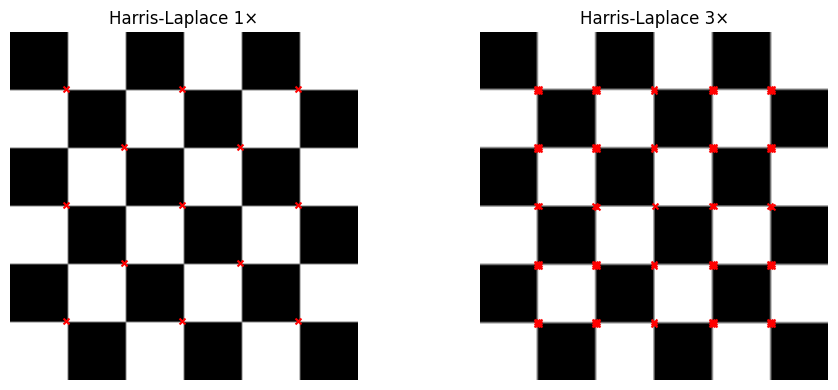

In [2]:
img_a=checkerboard_image((120,120),6); img_b=scale_image(img_a,3.0)
sa=scale_pyramid(.25,1.2,10); sb=scale_pyramid(.25,1.2,16)
ha=harris_classic(img_a); hb=harris_classic(img_b)
hla=harris_laplace(img_a,sa); hlb=harris_laplace(img_b,sb)
transform=lambda r,c:(3*r,3*c)
scale_rows=[
 {"Detector":"Harris","points_1x":len(ha),"points_3x":len(hb),"repeatability":repeatability(ha,hb,transform,img_b.shape,4)},
 {"Detector":"Harris-Laplace","points_1x":len(hla),"points_3x":len(hlb),"repeatability":repeatability(hla,hlb,transform,img_b.shape,4)}]
scale_df=pd.DataFrame(scale_rows); display(scale_df)
fig,ax=plt.subplots(1,2,figsize=(10,4)); plot_corners(img_a,hla,ax=ax[0],title="Harris-Laplace 1×"); plot_corners(img_b,hlb,ax=ax[1],title="Harris-Laplace 3×")
plt.tight_layout(); plt.savefig(OUT/"integrated_harris_laplace.png",dpi=160); plt.show()

## 2. Cặp A2 — Top-N và ANMS

,Method,selected,grid_occupancy_8x8
0,Top-N,100,0.250
1,ANMS,100,0.375


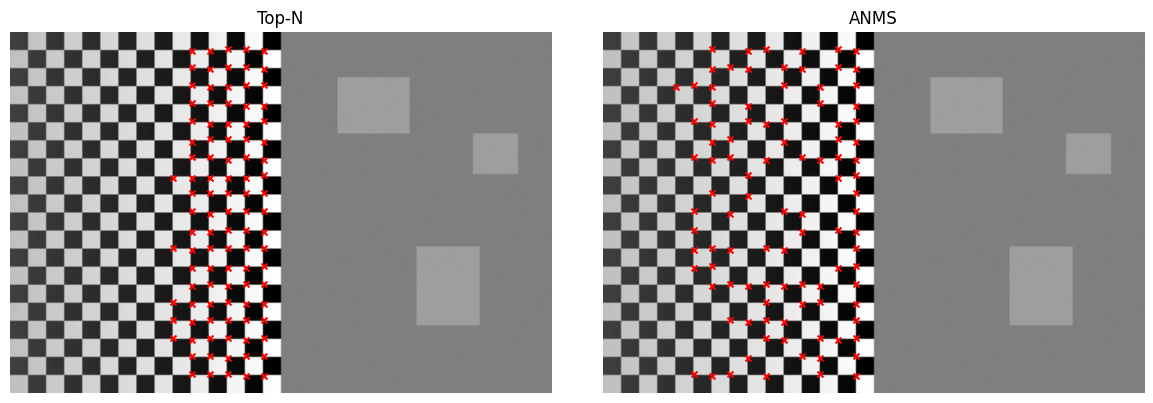

In [3]:
scene=anms_scene(); candidates=harris_classic(scene,sigma_i=1.5,sigma_d=1,thresh_rel=.002)
N=100; ptop=top_n(candidates,N); pans=anms(candidates,N,.9)
anms_df=pd.DataFrame([
 {"Method":"Top-N","selected":len(ptop),"grid_occupancy_8x8":grid_occupancy(ptop,scene.shape,8)},
 {"Method":"ANMS","selected":len(pans),"grid_occupancy_8x8":grid_occupancy(pans,scene.shape,8)}])
display(anms_df)
fig,ax=plt.subplots(1,2,figsize=(12,4)); plot_corners(scene,ptop,ax=ax[0],title="Top-N"); plot_corners(scene,pans,ax=ax[1],title="ANMS")
plt.tight_layout(); plt.savefig(OUT/"integrated_anms.png",dpi=160); plt.show()

## 3. Cặp B — Region Growing và SRG

,Method,regions,unassigned_pixels,full_partition
0,RG Stack,3,1,False
1,RG Queue,3,3,False
2,SRG,3,0,True


Stack vs Queue: {'common_labeled_pixels': 21597, 'different_partition_pixels': 0, 'different_percent_of_common': 0.0, 'unassigned_a': 1, 'unassigned_b': 3}
Stack vs SRG: {'common_labeled_pixels': 21599, 'different_partition_pixels': 0, 'different_percent_of_common': 0.0, 'unassigned_a': 1, 'unassigned_b': 0}
Queue vs SRG: {'common_labeled_pixels': 21597, 'different_partition_pixels': 0, 'different_percent_of_common': 0.0, 'unassigned_a': 3, 'unassigned_b': 0}


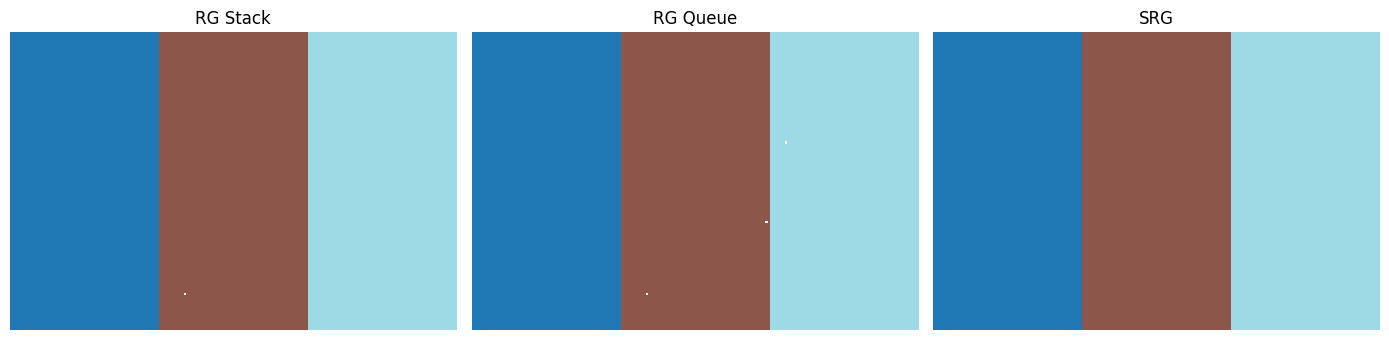

In [4]:
seg_img=segmentation_scene(); seeds=[(60,20),(60,90),(60,160)]
rg_stack=region_growing_classic(seg_img,seeds,T=25,order="stack")
rg_queue=region_growing_classic(seg_img,seeds,T=25,order="queue")
srg_labels,srg_boundary=srg(seg_img,seeds,stale="lazy",tie="insertion")
seg_rows=[]
for name,labels in [("RG Stack",rg_stack),("RG Queue",rg_queue),("SRG",srg_labels)]:
 seg_rows.append({"Method":name,"regions":count_regions(labels),"unassigned_pixels":int(np.sum(labels<0)),"full_partition":bool(np.all(labels>=0))})
seg_df=pd.DataFrame(seg_rows); display(seg_df)
print("Stack vs Queue:",partition_difference(rg_stack,rg_queue))
print("Stack vs SRG:",partition_difference(rg_stack,srg_labels))
print("Queue vs SRG:",partition_difference(rg_queue,srg_labels))
fig,ax=plt.subplots(1,3,figsize=(14,4)); plot_labels(rg_stack,ax=ax[0],title="RG Stack"); plot_labels(rg_queue,ax=ax[1],title="RG Queue"); plot_labels(srg_labels,ax=ax[2],title="SRG")
plt.tight_layout(); plt.savefig(OUT/"integrated_rg_srg.png",dpi=160); plt.show()

## 4. Xuất bảng kết quả

Các file CSV được lưu dưới `outputs/tables/`. Kết quả là số liệu thực chạy trên dữ liệu tổng hợp đi kèm project; khi thay ảnh, seed hoặc tham số, bảng sẽ thay đổi.

In [5]:
TABLES=ROOT/"outputs"/"tables"; TABLES.mkdir(parents=True,exist_ok=True)
scale_df.to_csv(TABLES/"harris_vs_harris_laplace.csv",index=False,encoding="utf-8-sig")
anms_df.to_csv(TABLES/"topn_vs_anms.csv",index=False,encoding="utf-8-sig")
seg_df.to_csv(TABLES/"region_growing_vs_srg.csv",index=False,encoding="utf-8-sig")
print("Đã lưu:")
for p in sorted(TABLES.glob("*.csv")): print("-",p.relative_to(ROOT))

Đã lưu:
- outputs/tables/harris_scale_comparison.csv
- outputs/tables/harris_vs_harris_laplace.csv
- outputs/tables/region_growing_srg_comparison.csv
- outputs/tables/region_growing_vs_srg.csv
- outputs/tables/topn_anms_comparison.csv
- outputs/tables/topn_vs_anms.csv


## 5. Cách viết kết luận báo cáo

Không kết luận “biến thể luôn tốt hơn”. Hãy nêu rõ:

- **Đại lượng thay đổi:** response Harris, LoG theo scale, bán kính ức chế, delta trong heap, hoặc trung bình vùng.
- **Bước thuật toán thay đổi:** lọc theo trục scale; xếp hạng ANMS; thứ tự ưu tiên heap thay cho ngưỡng T.
- **Hệ quả quan sát được:** số điểm/scale/độ phủ lưới/tỷ lệ lặp lại; pixel chưa gán/đường biên/độ nhạy seed.
- **Phạm vi kết luận:** ảnh, seed, tham số và phép đo đã dùng.